# Случайный лес: разнообразие деревьев и цена ансамбля

Одно дерево легко подстраивается под случайные детали обучающих заказов. Случайный лес обучает много деревьев на разных подвыборках и усредняет их оценки риска. Здесь мы разберём, откуда берётся разнообразие деревьев, что означает OOB-оценка и почему она не заменяет проверку более поздних заказов. Затем сравним качество, время и размер нескольких разумных конфигураций.

Мы сохраняем прежнюю задачу: оценить задержку при оформлении заказа по двенадцати доступным признакам. Train и validation разделены календарно с учётом семидневного появления метки. Окончательный тест не участвует в этом занятии. Все таблицы и графики уже получены выполнением ноутбука и относятся только к учебному синтетическому набору.

## Тот же контракт данных для ансамбля

Лес должен работать с теми же двенадцатью полями и тем же временем разделения, что и дерево. Подготовка числовых и категориальных признаков находится внутри `Pipeline`. Медианы и частые категории определяются только на train, а неизвестная категория в будущем заказе обрабатывается через `handle_unknown='ignore'`.

Сначала прочтём данные и создадим автономный конвейер. Дата заказа и дата появления метки нужны для аудита опыта, но не входят в признаки. Поля результата доставки также исключены.

**Импорты, признаки и чтение**

Импорты собраны один раз в первой кодовой ячейке. Таблица читается локально и сортируется по моменту заказа. Явный список признаков не позволит случайно включить поля, появляющиеся после доставки.

In [1]:
# Шаг М2.04.01 — Импорты, признаки и чтение
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score, f1_score, precision_score, recall_score, confusion_matrix

NUMERIC = ['distance_km', 'items_count', 'order_amount', 'warehouse_load', 'customer_prior_orders', 'promised_days', 'order_hour']
CATEGORICAL = ['city', 'product_category', 'delivery_type', 'weather_forecast', 'is_weekend']
FEATURES = NUMERIC + CATEGORICAL
data = pd.read_csv(Path('data/delivery_risk.csv'), parse_dates=['order_ts', 'label_available_at'])
data = data.sort_values('order_ts').reset_index(drop=True)
print('Строк:', len(data), 'признаков:', len(FEATURES), 'доля задержек:', round(data.late_delivery.mean(), 3))

Строк: 14000 признаков: 12 доля задержек: 0.126


**Временные границы и зрелость ответов**

Обучаемся на заказах до 25 июля и проверяем на заказах с 1 августа до 24 сентября. Метка последнего обучающего заказа должна появиться раньше первого заказа validation. Итоговый тест здесь не выбираем и не оцениваем.

In [2]:
# Шаг М2.04.02 — Временные границы и зрелость ответов
train = data.loc[data.order_ts < '2026-07-25'].copy()
validation = data.loc[(data.order_ts >= '2026-08-01') & (data.order_ts < '2026-09-24')].copy()
assert train.label_available_at.max() < validation.order_ts.min()
X_train, y_train = train[FEATURES], train.late_delivery
X_val, y_val = validation[FEATURES], validation.late_delivery
print(pd.DataFrame({'заказов': [len(train), len(validation)], 'доля_задержек': [y_train.mean(), y_val.mean()]}, index=['train', 'validation']).round(3))
print('Последняя метка train:', train.label_available_at.max(), 'Первый заказ validation:', validation.order_ts.min())

            заказов  доля_задержек
train          7863          0.118
validation     2072          0.115
Последняя метка train: 2026-07-31 23:42:27 Первый заказ validation: 2026-08-01 00:02:11


**Конвейеры дерева и леса**

Создадим одинаковую подготовку для обоих алгоритмов. `RandomForestClassifier` получает умеренное число деревьев и не использует больше двух рабочих процессов. Для сравнения позже создадим отдельное дерево с зафиксированными параметрами.

In [3]:
# Шаг М2.04.03 — Конвейеры дерева и леса
def make_prepare():
    return ColumnTransformer([
        ('numeric', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True))]), NUMERIC),
        ('categorical', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                                  ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CATEGORICAL),
    ])

def make_forest(**kwargs):
    params = dict(n_estimators=120, max_depth=9, min_samples_leaf=15, max_features=0.7, n_jobs=2, random_state=42)
    params.update(kwargs)
    return Pipeline([('prepare', make_prepare()), ('model', RandomForestClassifier(**params))])

def make_tree():
    return Pipeline([('prepare', make_prepare()), ('model', DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42))])

forest = make_forest().fit(X_train, y_train)
print('Деревьев:', len(forest.named_steps['model'].estimators_))
print('Подготовленных столбцов:', forest.named_steps['prepare'].transform(X_train.iloc[:1]).shape[1])

Деревьев: 120
Подготовленных столбцов: 43


**Базовый результат фиксированного леса**

Сразу проверим, что лес выдаёт вероятности и бинарные решения на позднем validation. Средняя точность AP описывает ранжирование задержек, а F1 относится к решениям при стандартном пороге.

In [4]:
# Шаг М2.04.04 — Базовый результат фиксированного леса
forest_p_train = forest.predict_proba(X_train)[:, 1]
forest_p_val = forest.predict_proba(X_val)[:, 1]
forest_y_val = forest.predict(X_val)
print(pd.Series({'AP_train': average_precision_score(y_train, forest_p_train),
                 'AP_validation': average_precision_score(y_val, forest_p_val),
                 'ROC_AUC_validation': roc_auc_score(y_val, forest_p_val),
                 'F1_validation': f1_score(y_val, forest_y_val)}).round(3).to_string())

AP_train              0.547
AP_validation         0.321
ROC_AUC_validation    0.719
F1_validation         0.183


У нас есть лес-кандидат на тех же признаках и временных границах. Теперь разберём, чем обучающие данные отдельных деревьев отличаются и почему разнообразие ответов позволяет усреднению работать.

## Bootstrap, случайные признаки и OOB

Каждое дерево леса обучается на bootstrap-выборке: из train случайно берутся строки с возвращением. Поэтому некоторые заказы повторяются, а часть вообще не попадает в выборку конкретного дерева. Эти оставшиеся строки называют out-of-bag, или OOB. При большом объёме доля OOB для одного дерева близка к 36,8%.

Дополнительно при каждом разбиении выбирается случайное подмножество признаков. Это мешает самым сильным полям неизменно диктовать одинаковые первые вопросы всем деревьям. Усреднение лучше сокращает нестабильность, когда ошибки деревьев не слишком сильно коррелируют. OOB-оценка полезна как внутренняя диагностика, но перемешивает время и не заменяет наш поздний validation.

**Одна bootstrap-выборка вручную**

Смоделируем выбор строк с возвращением и измерим долю уникальных и OOB-заказов. Этот маленький опыт показывает механизм без обучения дополнительной модели.

In [5]:
# Шаг М2.04.05 — Одна bootstrap-выборка вручную
rng = np.random.default_rng(42)
sampled = rng.integers(0, len(train), size=len(train))
unique_count = len(np.unique(sampled))
oob_count = len(train) - unique_count
print('Исходных заказов:', len(train))
print('Различных в bootstrap:', unique_count, 'доля:', round(unique_count/len(train), 3))
print('OOB для одного дерева:', oob_count, 'доля:', round(oob_count/len(train), 3))

Исходных заказов: 7863
Различных в bootstrap: 4955 доля: 0.63
OOB для одного дерева: 2908 доля: 0.37


**Разнообразие ответов отдельных деревьев**

После общего преобразования возьмём первые двадцать деревьев и их вероятности для одних и тех же validation-заказов. Сравним разброс ответов с усреднённой вероятностью всего леса.

In [6]:
# Шаг М2.04.06 — Разнообразие ответов отдельных деревьев
prepared_sample = forest.named_steps['prepare'].transform(X_val.iloc[:5])
individual = np.vstack([tree.predict_proba(prepared_sample)[:, 1] for tree in forest.named_steps['model'].estimators_[:20]])
diversity = pd.DataFrame({'среднее_20_деревьев': individual.mean(axis=0),
                          'стандартное_отклонение': individual.std(axis=0),
                          'ответ_леса': forest.predict_proba(X_val.iloc[:5])[:, 1]})
print(diversity.round(3).to_string(index=False))

 среднее_20_деревьев  стандартное_отклонение  ответ_леса
               0.113                   0.098       0.124
               0.139                   0.135       0.225
               0.059                   0.047       0.070
               0.111                   0.147       0.128
               0.275                   0.186       0.267


**Корреляция деревьев на validation**

Оценим корреляцию вероятностей нескольких деревьев по validation. Сильная общая закономерность делает ответы похожими; bootstrap и случайные признаки пытаются уменьшить лишнюю общность ошибок.

In [7]:
# Шаг М2.04.07 — Корреляция деревьев на validation
prepared_all_val = forest.named_steps['prepare'].transform(X_val)
individual_all = np.vstack([tree.predict_proba(prepared_all_val)[:, 1] for tree in forest.named_steps['model'].estimators_[:12]])
correlations = np.corrcoef(individual_all)
off_diagonal = correlations[np.triu_indices_from(correlations, k=1)]
print('Средняя корреляция вероятностей 12 деревьев:', round(np.nanmean(off_diagonal), 3))
print('Диапазон:', round(np.nanmin(off_diagonal), 3), '—', round(np.nanmax(off_diagonal), 3))

Средняя корреляция вероятностей 12 деревьев: 0.489
Диапазон: 0.42 — 0.549


**OOB-оценка ансамбля**

Обучим тот же лес с `oob_score=True`. По умолчанию `oob_score_` — accuracy для классов. Отдельно вычислим AP из OOB-вероятностей, чтобы не путать две метрики.

In [8]:
# Шаг М2.04.08 — OOB-оценка ансамбля
oob_forest = make_forest(oob_score=True).fit(X_train, y_train)
oob_probs = oob_forest.named_steps['model'].oob_decision_function_[:, 1]
print('OOB accuracy по умолчанию:', round(oob_forest.named_steps['model'].oob_score_, 3))
print('OOB AP по вероятностям:', round(average_precision_score(y_train, oob_probs), 3))
print('AP позднего validation:', round(average_precision_score(y_val, oob_forest.predict_proba(X_val)[:, 1]), 3))

OOB accuracy по умолчанию: 0.887
OOB AP по вероятностям: 0.335
AP позднего validation: 0.321


**Вывод по OOB.** В сохранённом результате OOB accuracy равна приблизительно 0,888, а OOB AP — 0,335. Эти числа нельзя сравнивать как две версии одной метрики. AP более позднего validation составляет около 0,324: она получена на следующем календарном периоде, а OOB-прогнозы собирались внутри раннего train. Поэтому даже похожие значения не делают OOB заменой временного разделения.

**Почему OOB не является временным тестом**

Покажем на индексах одной bootstrap-выборки: среди выбранных для дерева заказов встречаются строки позднее некоторого OOB-заказа. Следовательно, OOB сохраняет независимость от данного дерева по строке, но не причинный порядок времени.

In [9]:
# Шаг М2.04.09 — Почему OOB не является временным тестом
oob_indices = np.setdiff1d(np.arange(len(train)), np.unique(sampled))
example_oob = oob_indices[len(oob_indices)//2]
later_in_bootstrap = sampled[sampled > example_oob]
print('OOB-заказ:', train.iloc[example_oob].order_ts)
print('Поздних обучающих заказов для этого дерева:', len(later_in_bootstrap))
print('Самый поздний из них:', train.iloc[later_in_bootstrap].order_ts.max())

OOB-заказ: 2026-04-17 13:28:19
Поздних обучающих заказов для этого дерева: 3723
Самый поздний из них: 2026-07-24 23:04:55


Bootstrap оставляет примерно треть заказов вне выборки отдельного дерева, случайные признаки уменьшают сходство правил, а усреднение стабилизирует ответ. OOB-сигнал удобен, но не проверяет временной перенос; дальше будем сравнивать конфигурации на validation.

## Настройки леса и вычислительная цена

Число деревьев повышает устойчивость среднего, но увеличивает время обучения и размер модели почти линейно. Глубина и минимальный размер листа влияют на сложность каждого дерева, а `max_features` регулирует случайность вопросов. Мы меняем по одному параметру относительно фиксированного кандидата и наблюдаем AP на validation вместе с затратами.

Параметр `class_weight='balanced'` уже знаком: он увеличивает вес редкого класса при обучении. Здесь оценим фактическое изменение precision, recall и AP, не предполагая заранее улучшения. Все варианты остаются умеренными по размеру для локального запуска.

**Количество деревьев и время**

Сравним 20, 60 и 120 деревьев при неизменных остальных параметрах. Замерим время `fit`, AP и число узлов в ансамбле. Последняя величина грубо отражает память, которую занимают правила.

In [10]:
# Шаг М2.04.10 — Количество деревьев и время
size_rows = []
for count in [20, 60, 120]:
    start = perf_counter()
    pipe = make_forest(n_estimators=count).fit(X_train, y_train)
    seconds = perf_counter() - start
    size_rows.append({'деревьев': count, 'время_обучения_с': seconds,
                      'AP_validation': average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1]),
                      'узлов_всего': sum(tree.tree_.node_count for tree in pipe.named_steps['model'].estimators_)})
size_results = pd.DataFrame(size_rows)
print(size_results.round(3).to_string(index=False))

 деревьев  время_обучения_с  AP_validation  узлов_всего
       20             0.142          0.306         4848
       60             0.378          0.319        14346
      120             0.754          0.321        28608


**График насыщения ансамбля**

Покажем AP и время по числу деревьев на двух осях. Нас интересует область, где прибавка качества становится мала относительно дополнительных вычислений.

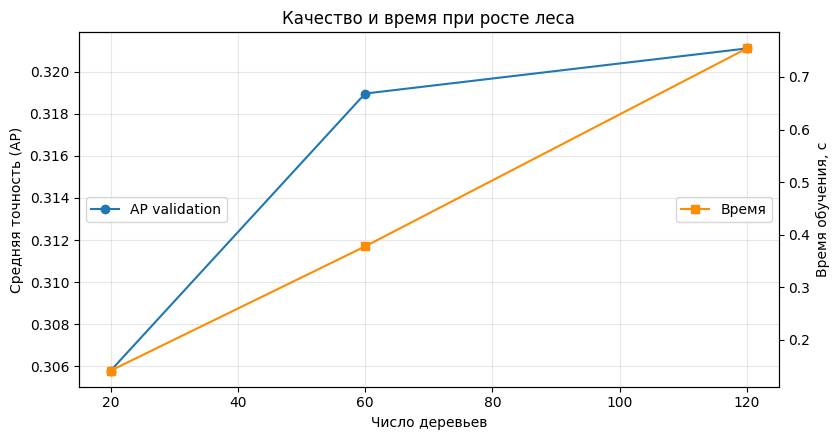

In [11]:
# Шаг М2.04.11 — График насыщения ансамбля
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(size_results['деревьев'], size_results['AP_validation'], marker='o', label='AP validation')
ax.set(xlabel='Число деревьев', ylabel='Средняя точность (AP)', title='Качество и время при росте леса')
ax.grid(alpha=.3)
ax2 = ax.twinx()
ax2.plot(size_results['деревьев'], size_results['время_обучения_с'], color='darkorange', marker='s', label='Время')
ax2.set_ylabel('Время обучения, с')
ax.legend(loc='center left'); ax2.legend(loc='center right'); plt.tight_layout(); plt.show()

**Доля признаков на разбиении**

Сравним три доли `max_features`, сохраняя сто двадцать деревьев. Меньшая доля обычно повышает разнообразие, но каждый узел может упустить полезный вопрос.

In [12]:
# Шаг М2.04.12 — Доля признаков на разбиении
feature_rows = []
for fraction in [0.4, 0.7, 1.0]:
    pipe = make_forest(max_features=fraction).fit(X_train, y_train)
    feature_rows.append({'max_features': fraction,
                         'AP_validation': average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1]),
                         'средняя_глубина': np.mean([tree.get_depth() for tree in pipe.named_steps['model'].estimators_])})
print(pd.DataFrame(feature_rows).round(3).to_string(index=False))

 max_features  AP_validation  средняя_глубина
          0.4          0.327              9.0
          0.7          0.321              9.0
          1.0          0.319              9.0


**Глубина и размер листа**

Проверим несколько сочетаний ограничений отдельного дерева. Эти параметры могут уменьшить шум в вероятностях и одновременно сократить объём ансамбля.

In [13]:
# Шаг М2.04.13 — Глубина и размер листа
shape_rows = []
for depth, leaf in [(6, 15), (9, 5), (9, 15), (9, 30), (12, 15)]:
    pipe = make_forest(max_depth=depth, min_samples_leaf=leaf, n_estimators=80).fit(X_train, y_train)
    shape_rows.append({'глубина': depth, 'минимум_в_листе': leaf,
                       'AP_validation': average_precision_score(y_val, pipe.predict_proba(X_val)[:, 1]),
                       'узлов_всего': sum(t.tree_.node_count for t in pipe.named_steps['model'].estimators_)})
print(pd.DataFrame(shape_rows).round(3).to_string(index=False))

 глубина  минимум_в_листе  AP_validation  узлов_всего
       6               15          0.329         7458
       9                5          0.310        26646
       9               15          0.322        19160
       9               30          0.334        13720
      12               15          0.320        26476


**Влияние веса редкого класса**

Сравним стандартные веса и `class_weight='balanced'` при остальных фиксированных параметрах. Выведем AP, precision, recall, F1 и число предупреждений на validation, чтобы увидеть реальный обмен ошибок.

In [14]:
# Шаг М2.04.14 — Влияние веса редкого класса
weight_rows = []
for label, setting in [('обычные', None), ('balanced', 'balanced')]:
    pipe = make_forest(class_weight=setting).fit(X_train, y_train)
    probabilities = pipe.predict_proba(X_val)[:, 1]
    predictions = pipe.predict(X_val)
    weight_rows.append({'веса': label, 'AP': average_precision_score(y_val, probabilities),
                        'precision': precision_score(y_val, predictions, zero_division=0),
                        'recall': recall_score(y_val, predictions, zero_division=0),
                        'F1': f1_score(y_val, predictions), 'предупреждений': int(predictions.sum())})
print(pd.DataFrame(weight_rows).round(3).to_string(index=False))

    веса    AP  precision  recall    F1  предупреждений
 обычные 0.321      0.578   0.109 0.183              45
balanced 0.322      0.289   0.494 0.365             408


**Вывод по весам.** На validation балансировка повысила recall примерно с 0,109 до 0,481, но снизила precision с 0,565 до 0,280. Количество предупреждений выросло с 46 до 411, тогда как AP почти не изменилась. Это конкретный пример обмена видов ошибок: редкий класс получил больше внимания при бинарном решении, но оператору пришлось бы разбирать гораздо больше тревог. Выбор такой политики требует цены каждого действия, которой в учебных данных нет.

**Фиксация вычислительного компромисса**

Сведём характеристики выбранного леса: число деревьев, общие узлы, средняя глубина и AP validation. Конфигурация заранее определена для сравнения моделей курса, а не выбрана после просмотра итогового теста.

In [15]:
# Шаг М2.04.15 — Фиксация вычислительного компромисса
forest_model = forest.named_steps['model']
forest_cost = pd.Series({'деревьев': len(forest_model.estimators_),
                         'узлов_всего': sum(t.tree_.node_count for t in forest_model.estimators_),
                         'средняя_глубина': np.mean([t.get_depth() for t in forest_model.estimators_]),
                         'AP_validation': average_precision_score(y_val, forest_p_val)})
print(forest_cost.round(3).to_string())

деревьев             120.000
узлов_всего        28608.000
средняя_глубина        9.000
AP_validation          0.321


Качество меняется вместе с вычислительной стоимостью. Число деревьев, глубина, размер листа и доля доступных признаков влияют на разные стороны ансамбля; `class_weight` также меняет фактический баланс ошибок. Дальше подробно рассмотрим ошибки фиксированного кандидата.

## Прогнозы, ошибки и порог

Лес усредняет вероятности отдельных деревьев, а `predict` превращает их в классы при стандартном пороге. Для задержек меньшинства полезно смотреть не только на одну метрику, но и на состав ошибок. Мы сравним фиксированный лес с фиксированным деревом при одинаковом разбиении и подготовке, а также покажем, как порог меняет число предупреждений.

Здесь не выбираем окончательный рабочий порог: цена ложного предупреждения и пропущенной задержки не задана. Все выводы ограничены синтетическим validation.

**Матрица ошибок леса**

Покажем четыре числа для стандартного решения леса. Они раскрывают, сколько задержек поймано и сколько своевременных заказов получили ложное предупреждение.

In [16]:
# Шаг М2.04.16 — Матрица ошибок леса
forest_matrix = confusion_matrix(y_val, forest_y_val)
print(pd.DataFrame(forest_matrix, index=['факт: вовремя', 'факт: задержка'],
                   columns=['прогноз: вовремя', 'прогноз: задержка']))
print('Precision:', round(precision_score(y_val, forest_y_val, zero_division=0), 3),
      'Recall:', round(recall_score(y_val, forest_y_val, zero_division=0), 3))

                прогноз: вовремя  прогноз: задержка
факт: вовремя               1814                 19
факт: задержка               213                 26
Precision: 0.578 Recall: 0.109


**Распределение оценок риска**

Сравним вероятности для своевременных и задержанных заказов на validation. Перекрытие распределений показывает, почему один порог не способен отделить все классы без ошибок.

При density=True высота показывает плотность: площадь всех столбцов с учётом их ширины равна единице. Сумма высот не обязана быть единицей, а отдельная высота может превышать один. Для каждого класса распределение нормировано отдельно, поэтому рисунок сравнивает форму рисков, а не общее число заявок классов.

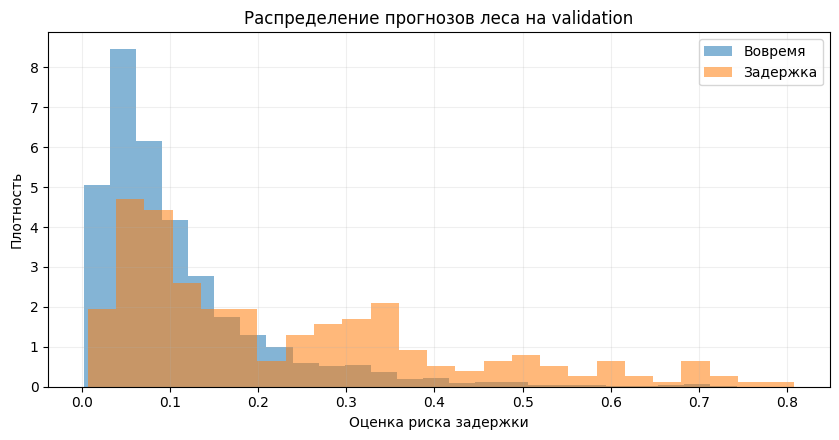

In [17]:
# Шаг М2.04.17 — Распределение оценок риска
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.hist(forest_p_val[y_val.to_numpy() == 0], bins=25, density=True, alpha=.55, label='Вовремя')
ax.hist(forest_p_val[y_val.to_numpy() == 1], bins=25, density=True, alpha=.55, label='Задержка')
ax.set(xlabel='Оценка риска задержки', ylabel='Плотность', title='Распределение прогнозов леса на validation')
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()

**Три рабочих порога как опыт**

Сравним несколько порогов без выбора победителя. При уменьшении порога обычно растёт число предупреждений и полнота, но может падать точность предупреждений.

In [18]:
# Шаг М2.04.18 — Три рабочих порога как опыт
threshold_rows = []
for threshold in [0.2, 0.35, 0.5]:
    pred = (forest_p_val >= threshold).astype(int)
    threshold_rows.append({'порог': threshold, 'предупреждений': int(pred.sum()),
                           'precision': precision_score(y_val, pred, zero_division=0),
                           'recall': recall_score(y_val, pred, zero_division=0),
                           'F1': f1_score(y_val, pred)})
print(pd.DataFrame(threshold_rows).round(3).to_string(index=False))

 порог  предупреждений  precision  recall    F1
  0.20             341      0.305   0.435 0.359
  0.35             113      0.451   0.213 0.290
  0.50              45      0.578   0.109 0.183


**Дерево и лес при равных условиях**

Обучим фиксированное дерево из прошлого занятия на том же train. Сравним AP, ROC-AUC и F1 на одном validation. Разница характеризует именно эти модели и этот период.

In [19]:
# Шаг М2.04.19 — Дерево и лес при равных условиях
single_tree = make_tree().fit(X_train, y_train)
tree_p_val = single_tree.predict_proba(X_val)[:, 1]
tree_y_val = single_tree.predict(X_val)
model_comparison = pd.DataFrame([
    {'модель': 'Дерево', 'AP': average_precision_score(y_val, tree_p_val), 'ROC-AUC': roc_auc_score(y_val, tree_p_val), 'F1': f1_score(y_val, tree_y_val)},
    {'модель': 'Случайный лес', 'AP': average_precision_score(y_val, forest_p_val), 'ROC-AUC': roc_auc_score(y_val, forest_p_val), 'F1': f1_score(y_val, forest_y_val)}])
print(model_comparison.round(3).to_string(index=False))

       модель    AP  ROC-AUC    F1
       Дерево 0.296    0.697 0.186
Случайный лес 0.321    0.719 0.183


Лес выдаёт более плавные оценки за счёт усреднения, но конкретные ошибки зависят от порога и данных. Сравнение с деревом проведено на равных условиях. Следующий шаг — проверить, на какие исходные поля прогноз опирается на validation.

## Важность на validation и ограничения интерпретации

Встроенная `feature_importances_` леса суммирует снижение смешанности в деревьях на обучении. В занятии про дерево мы увидели пределы этой меры. `permutation_importance` отвечает на другой вопрос: что произойдёт с качеством готового конвейера на validation, если перемешать значения одного исходного признака между заказами? Мы передадим функции сырые двенадцать столбцов, поэтому она нарушит весь исходный признак сразу, а подготовка останется внутри `Pipeline`.

Падение AP после перемешивания указывает на зависимость прогноза от признака на данном validation. Коррелирующие поля могут подменять друг друга и скрывать индивидуальную важность. Перемешивание также создаёт искусственные сочетания признаков. Ни эта оценка, ни встроенная важность не доказывают причинного влияния поля на задержку.

**Перестановочная важность сырых полей**

Вызовем `permutation_importance` для всего `Pipeline` на `X_val` с двенадцатью исходными столбцами. Три повтора дают представление о разбросе случайной перестановки при умеренной вычислительной стоимости.

In [20]:
# Шаг М2.04.20 — Перестановочная важность сырых полей
permutation = permutation_importance(forest, X_val, y_val, scoring='average_precision',
                                     n_repeats=3, random_state=42, n_jobs=1)
permutation_table = pd.DataFrame({'признак': FEATURES,
                                  'среднее_падение_AP': permutation.importances_mean,
                                  'разброс': permutation.importances_std}).sort_values('среднее_падение_AP', ascending=False)
print(permutation_table.round(4).to_string(index=False))

              признак  среднее_падение_AP  разброс
       warehouse_load              0.1553   0.0128
          distance_km              0.0426   0.0063
     weather_forecast              0.0361   0.0082
        delivery_type              0.0300   0.0031
        promised_days              0.0241   0.0039
     product_category              0.0000   0.0004
          items_count             -0.0005   0.0003
customer_prior_orders             -0.0009   0.0004
         order_amount             -0.0012   0.0083
                 city             -0.0016   0.0006
           is_weekend             -0.0021   0.0024
           order_hour             -0.0038   0.0024


**Вывод по важности.** В этом validation перемешивание загрузки склада сильнее всего ухудшило AP. Для ряда полей падение близко к нулю или даже немного отрицательно: это возможный шум перестановки и подмена информации другими полями, а не доказательство отсутствия связи. При интерпретации сохраняем единицы измерения: показаны абсолютные пункты AP, а не проценты задержанных заказов.

**График перестановочной важности**

Покажем падение AP с полосами разброса по трём перестановкам. Подписи остаются именами исходных двенадцати полей, без дробления категорий на индикаторы.

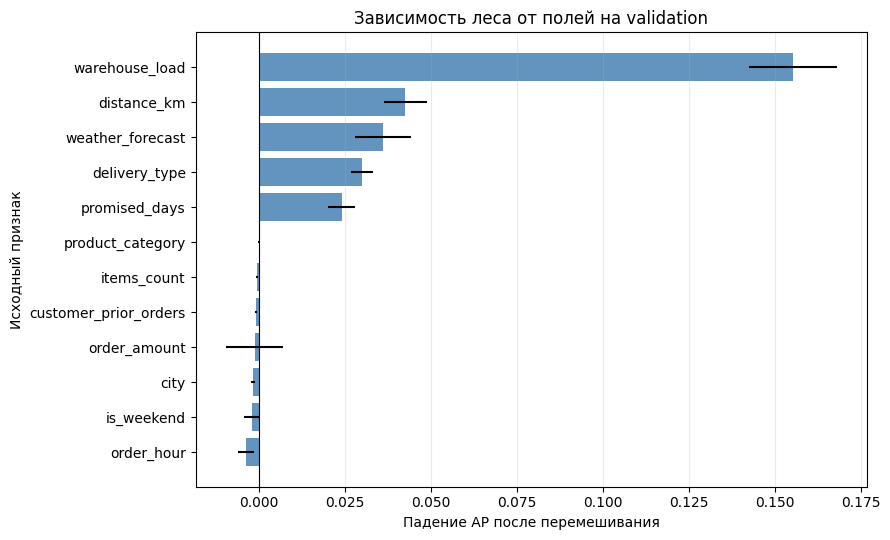

In [21]:
# Шаг М2.04.21 — График перестановочной важности
ordered = permutation_table.sort_values('среднее_падение_AP')
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(ordered['признак'], ordered['среднее_падение_AP'], xerr=ordered['разброс'], color='steelblue', alpha=.85)
ax.axvline(0, color='black', linewidth=.8)
ax.set(xlabel='Падение AP после перемешивания', ylabel='Исходный признак', title='Зависимость леса от полей на validation')
ax.grid(axis='x', alpha=.25); plt.tight_layout(); plt.show()

**Встроенная важность леса**

Для сопоставления агрегируем impurity-важности кодированных столбцов по исходным полям. Они вычислены на train, поэтому ранги могут отличаться от падения AP на validation.

In [22]:
# Шаг М2.04.22 — Встроенная важность леса
encoded_names = forest.named_steps['prepare'].get_feature_names_out()
encoded_importance = pd.Series(forest.named_steps['model'].feature_importances_, index=encoded_names)
raw_impurity = {}
for raw in FEATURES:
    if raw in NUMERIC:
        mask = [name == f'numeric__{raw}' or name == f'numeric__missingindicator_{raw}' for name in encoded_names]
    else:
        mask = [name.startswith(f'categorical__{raw}_') for name in encoded_names]
    raw_impurity[raw] = encoded_importance.loc[mask].sum()
importance_comparison = permutation_table.set_index('признак')[['среднее_падение_AP']].join(pd.Series(raw_impurity, name='снижение_Джини_на_train'))
print(importance_comparison.round(4).to_string())

                       среднее_падение_AP  снижение_Джини_на_train
признак                                                           
warehouse_load                     0.1553                   0.2932
distance_km                        0.0426                   0.2108
weather_forecast                   0.0361                   0.0824
delivery_type                      0.0300                   0.0689
promised_days                      0.0241                   0.0564
product_category                   0.0000                   0.0288
items_count                       -0.0005                   0.0148
customer_prior_orders             -0.0009                   0.0337
order_amount                      -0.0012                   0.1082
city                              -0.0016                   0.0208
is_weekend                        -0.0021                   0.0216
order_hour                        -0.0038                   0.0604


**Корреляции числовых признаков**

Проверим корреляцию числовых исходных полей на train. Сильная связь означает, что один признак может частично заменить другой при прогнозе; индивидуальная перестановочная важность тогда бывает занижена.

In [23]:
# Шаг М2.04.23 — Корреляции числовых признаков
numeric_corr = X_train[NUMERIC].corr()
pairs = []
for i, first in enumerate(NUMERIC):
    for second in NUMERIC[i+1:]:
        pairs.append((first, second, numeric_corr.loc[first, second]))
correlation_table = pd.DataFrame(pairs, columns=['первый', 'второй', 'корреляция'])
correlation_table['модуль'] = correlation_table['корреляция'].abs()
print(correlation_table.sort_values('модуль', ascending=False).head(8).drop(columns='модуль').round(3).to_string(index=False))

               первый                второй  корреляция
          items_count          order_amount       0.022
         order_amount customer_prior_orders       0.019
         order_amount            order_hour      -0.018
       warehouse_load            order_hour       0.018
         order_amount         promised_days       0.018
          distance_km customer_prior_orders      -0.017
          items_count            order_hour      -0.016
customer_prior_orders         promised_days       0.015


**Проверка незнакомой категории**

Validation может содержать город, отсутствовавший в train. Убедимся, что конвейер выдаёт конечные вероятности для таких строк: `OneHotEncoder(handle_unknown='ignore')` создан именно для этого случая.

In [24]:
# Шаг М2.04.24 — Проверка незнакомой категории
unknown_cities = sorted(set(X_val['city'].dropna()) - set(X_train['city'].dropna()))
unknown_mask = X_val['city'].isin(unknown_cities)
print('Новые города:', unknown_cities, 'заказов:', int(unknown_mask.sum()))
if unknown_mask.any():
    unknown_prob = forest.predict_proba(X_val.loc[unknown_mask])[:, 1]
    assert np.isfinite(unknown_prob).all()
    print('Диапазон прогнозов для нового города:', round(float(unknown_prob.min()), 3), '—', round(float(unknown_prob.max()), 3))

Новые города: [] заказов: 0


Перестановочная важность на validation оценила зависимость качества от исходных двенадцати полей, а встроенная важность показала распределение снижений Джини на train. Корреляции и незнакомые категории ограничивают интерпретацию. Ни один показатель не является причинным объяснением.

## Итоговый профиль кандидата

Ансамбль обменивает прозрачность одного дерева на более устойчивое усреднение и дополнительные вычисления. Сравним время прогноза, число хранимых узлов и параметры фиксированного кандидата. Это не промышленный бенчмарк, а локальная оценка масштаба затрат.

Итоговая модель для следующего занятия: `RandomForestClassifier(n_estimators=120, max_depth=9, min_samples_leaf=15, max_features=0.7, n_jobs=2, random_state=42)` внутри того же `Pipeline`. Здесь зафиксированы только результаты validation; окончательный тест остаётся для общего сравнения.

**Время предсказания на validation**

Замерим один последовательный вызов `predict_proba` дерева и леса для всего validation. Время может колебаться между запусками, поэтому используем его как иллюстрацию дополнительной работы ансамбля.

In [25]:
# Шаг М2.04.25 — Время предсказания на validation
timing_rows = []
for label, pipe in [('Дерево', single_tree), ('Случайный лес', forest)]:
    start = perf_counter()
    probabilities = pipe.predict_proba(X_val)[:, 1]
    elapsed = perf_counter() - start
    timing_rows.append({'модель': label, 'время_прогноза_с': elapsed, 'заказов': len(probabilities)})
print(pd.DataFrame(timing_rows).round(4).to_string(index=False))

       модель  время_прогноза_с  заказов
       Дерево            0.0051     2072
Случайный лес            0.0276     2072


**Число правил в памяти**

Сравним число узлов одного дерева и сумму узлов леса. Это не точный объём файла в байтах, но понятный показатель масштаба хранимых разбиений.

In [26]:
# Шаг М2.04.26 — Число правил в памяти
tree_nodes = single_tree.named_steps['model'].tree_.node_count
forest_nodes = sum(t.tree_.node_count for t in forest.named_steps['model'].estimators_)
print(pd.DataFrame({'модель': ['Дерево', 'Случайный лес'], 'узлов': [tree_nodes, forest_nodes]}).to_string(index=False))
print('Отношение по числу узлов:', round(forest_nodes/tree_nodes, 1))

       модель  узлов
       Дерево     53
Случайный лес  28608
Отношение по числу узлов: 539.8


**Фиксированные настройки для общего теста**

Выведем параметры кандидата и validation-метрики. Они станут исходной точкой общего сравнения моделей, где итоговый тест будет обработан только после завершения выбора.

In [27]:
# Шаг М2.04.27 — Фиксированные настройки для общего теста
final_profile = pd.Series({'модель': 'RandomForestClassifier', 'n_estimators': 120, 'max_depth': 9,
                           'min_samples_leaf': 15, 'max_features': 0.7, 'n_jobs': 2, 'random_state': 42,
                           'AP_validation': average_precision_score(y_val, forest_p_val),
                           'ROC_AUC_validation': roc_auc_score(y_val, forest_p_val),
                           'F1_validation': f1_score(y_val, forest_y_val)})
print(final_profile.to_string())

модель                RandomForestClassifier
n_estimators                             120
max_depth                                  9
min_samples_leaf                          15
max_features                             0.7
n_jobs                                     2
random_state                              42
AP_validation                       0.321099
ROC_AUC_validation                  0.719017
F1_validation                       0.183099


Фиксированный лес готов для общего сравнения. Мы знаем его качество на validation, цену в числе узлов и локальное время прогноза. Эти результаты описывают учебный снимок данных и не гарантируют превосходства ансамбля на другом периоде.

## Полученный результат

Мы вручную увидели bootstrap и OOB, проверили разнообразие ответов деревьев и убедились, что OOB-оценка по умолчанию является accuracy, а не временным тестом. Настройки леса исследованы вместе с их вычислительной ценой; `class_weight='balanced'` оценён по фактическим изменениям метрик. Сравнение с деревом проведено на одинаковых train, validation, признаках и подготовке.

Перестановочная важность рассчитана для исходных двенадцати полей на validation через полный `Pipeline`. Она дополняет встроенную важность по снижению Джини, но обе оценки ограничены корреляциями и свойствами синтетического набора. Для общего сравнения оставлен фиксированный лес со 120 деревьями, глубиной до 9, минимумом 15 заказов в листе и `max_features=0.7`. Его сохранённые показатели относятся только к validation; итоговый тест будет использован в заключительном занятии.

## Документация

[RandomForestClassifier в документации scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)

[Перестановочная важность в руководстве scikit-learn](https://scikit-learn.org/stable/modules/permutation_importance.html)

[Bagging и случайные леса в руководстве scikit-learn](https://scikit-learn.org/stable/modules/ensemble.html#forest)